This notebook evaluates the performance of Model 4 (Presence-Only Detection) on video footage and explores potential approaches for extracting meaningful safety-related information from construction site images.

The main objective is to examine how the trained model performs in more dynamic visual environments and investigate methods for organizing object detections into interpretable analytics.

Particular attention is given to PPE detection, the association of detected equipment with individual workers, and the potential use of these detections to support construction site safety monitoring.

# Import model

In [1]:
!pip install -q ultralytics

from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [31]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
model = YOLO(
    "/content/drive/MyDrive/PPE_Construction_YOLO/weights/model4.pt"
)

# Video test

In [ ]:
video_path = "/content/drive/MyDrive/PPE_Construction_YOLO/test/video1.mp4"

In [ ]:
test = model.predict(
    source=video_path,
    imgsz=960,
    conf=0.25,
    save=True,
    project="/content/drive/MyDrive/PPE_Construction_YOLO",
    name="video_predictions",
    exist_ok=True
)


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/145) /content/drive/MyDrive/PPE_Construction_YOLO/test/video1.mp4: 544x960 2 helmets, 1 gloves, 2 vests, 1 boots, 2 Persons, 449.8ms
video 1/1 (frame 2/145) /content/drive/MyDrive/PPE_Construction_YOLO/test/video1.mp4: 544x960 2 helmets, 1 gloves, 2 vests, 1 boots, 2 Persons, 346.7ms
video 1/1 (frame 3/145) /content/drive/MyDrive/PPE_Construction_YOLO/test/video1.mp4: 544x960 2 helmets, 1 gloves, 2 vests, 1 boots, 1 Person, 224.2ms
vide

In [ ]:
import glob
import os
import subprocess

output_dir = "/content/drive/MyDrive/PPE_Construction_YOLO/video_predictions"

video_files = glob.glob(os.path.join(output_dir, "*.avi")) + \
              glob.glob(os.path.join(output_dir, "*.mp4"))

print(video_files)

['/content/drive/MyDrive/PPE_Construction_YOLO/video_predictions/video1.avi', '/content/drive/MyDrive/PPE_Construction_YOLO/video_predictions/video1_converted.mp4', '/content/drive/MyDrive/PPE_Construction_YOLO/video_predictions/video3_converted.mp4', '/content/drive/MyDrive/PPE_Construction_YOLO/video_predictions/video4_converted.mp4']


In [ ]:
input_video = video_files[0]
converted_video = os.path.join(output_dir, "video4_converted.mp4")

subprocess.run([
    "ffmpeg", "-y",
    "-i", input_video,
    "-vcodec", "libx264",
    "-pix_fmt", "yuv420p",
    "-an",
    converted_video
], check=True)

CompletedProcess(args=['ffmpeg', '-y', '-i', '/content/drive/MyDrive/PPE_Construction_YOLO/video_predictions/video1.avi', '-vcodec', 'libx264', '-pix_fmt', 'yuv420p', '-an', '/content/drive/MyDrive/PPE_Construction_YOLO/video_predictions/video4_converted.mp4'], returncode=0)

## Display video

In [ ]:
from IPython.display import Video, display

display(Video(converted_video, embed=True, width=800))

Output hidden; open in https://colab.research.google.com to view.

# Metrics

For the purpose of  making reports that include each worker's individual safety equipment there is a challenge because the model can detect objects but cannot assign each one of them to each worker. To address this problem I consider two approaches:

1. If a significant portion of a box is included in a person's box it would be considered as if this person has its safety equipment. Observations: if there is more than one persons overlapping in the photo the algorithn  won't work appropiately.

2. Can be considered a method that uses Yolo26 pose model to make a heat map of each person in order asociate each safety equipment appropiately.

## First approach

In [40]:
def calculate_overlap(person_box, ppe_box):

    px1, py1, px2, py2 = person_box
    ex1, ey1, ex2, ey2 = ppe_box

    x1 = max(px1, ex1)
    y1 = max(py1, ey1)
    x2 = min(px2, ex2)
    y2 = min(py2, ey2)

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    ppe_area = max(0, ex2 - ex1) * max(0, ey2 - ey1)

    if ppe_area == 0:
        return 0

    return intersection / ppe_area



def associate_ppe(persons, ppe_objects, threshold=0.5):

    associations = {
        i: [] for i in range(len(persons))
    }

    unassigned = []

    for obj in ppe_objects:

        best_person = None
        best_overlap = 0

        for person_id, person in enumerate(persons):

            overlap = calculate_overlap(
                person["box"],
                obj["box"]
            )

            if overlap > best_overlap:
                best_overlap = overlap
                best_person = person_id

        if best_person is not None and best_overlap >= threshold:

            obj["overlap"] = best_overlap

            associations[best_person].append(obj)

        else:
            unassigned.append(obj)

    return associations, unassigned


In [41]:
import pandas as pd

PERSON_CLASS = "Person"

PPE_CLASSES = [
    "helmet",
    "gloves",
    "vest",
    "boots",
    "goggles"
]


def analyze_ppe_image(model, image, threshold=0.5, conf=0.25):

    results = model.predict(
        source=image,
        conf=conf,
        verbose=False
    )

    result = results[0]

    persons = []
    ppe_objects = []

    names = model.names

    for box in result.boxes:

        cls_id = int(box.cls[0])
        cls_name = names[cls_id]

        detection = {
            "box": box.xyxy[0].cpu().numpy(),
            "confidence": float(box.conf[0]),
            "class": cls_name
        }

        if cls_name == PERSON_CLASS:

            persons.append(detection)

        elif cls_name in PPE_CLASSES:

            ppe_objects.append(detection)

    associations, unassigned = associate_ppe(
        persons,
        ppe_objects,
        threshold=threshold
    )

    rows = []

    for person_id, person in enumerate(persons):

        assigned = associations[person_id]

        row = {
            "Person": person_id + 1,
            "Total equipment": len(assigned)
        }

        for ppe in PPE_CLASSES:

            count = sum(
                obj["class"] == ppe
                for obj in assigned
            )

            row[ppe] = count

        rows.append(row)

    df = pd.DataFrame(rows)

    return df, associations, unassigned, result, persons


In [42]:
import cv2
import matplotlib.pyplot as plt

def visualize_associations(image_path, persons, associations):

    image = cv2.imread(image_path)

    for person_id, person in enumerate(persons):

        x1, y1, x2, y2 = map(int, person["box"])

        cv2.rectangle(
            image, (x1, y1), (x2, y2),
            (255, 0, 0), 3
        )

        cv2.putText(
            image,
            f"Person {person_id + 1}",
            (x1, max(20, y1 - 10)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7, (255, 0, 0), 2
        )

        for obj in associations[person_id]:

            ox1, oy1, ox2, oy2 = map(int, obj["box"])

            cv2.rectangle(
                image, (ox1, oy1), (ox2, oy2),
                (0, 255, 0), 2
            )

            cv2.putText(
                image,
                f'{obj["class"]}: {obj["overlap"]:.2f}',
                (ox1, max(20, oy1 - 5)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5, (0, 255, 0), 2
            )

    plt.figure(figsize=(15, 10))
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()

In [44]:
from IPython.display import display, Image
import pandas as pd

img_paths = [
    "/content/drive/MyDrive/PPE_Construction_YOLO/test/img1.jpg",
    "/content/drive/MyDrive/PPE_Construction_YOLO/test/img2.jpg",
    "/content/drive/MyDrive/PPE_Construction_YOLO/test/img3.jpg",
    "/content/drive/MyDrive/PPE_Construction_YOLO/test/img4.jpg"
]


results_by_image = {}

for image_path in img_paths:

    df, associations, unassigned, result, persons = analyze_ppe_image(
        model,
        image_path,
        threshold=0.5
    )

    results_by_image[image_path] = {
        "df": df,
        "associations": associations,
        "unassigned": unassigned,
        "result": result,
        "persons": persons
    }

    print(f"\nResults for: {image_path.split('/')[-1]}")

    display(df)

    visualize_associations(
        image_path,
        persons,
        associations
    )



Output hidden; open in https://colab.research.google.com to view.

This images show that this approach only works appropriately when persons are not overlapping.

## Second approach

### Obteining model that recognizes poses and testing it

In [ ]:

from IPython.display import display, Image
import pandas as pd

img_paths = [
    "/content/drive/MyDrive/PPE_Construction_YOLO/test/img1.jpg",
    "/content/drive/MyDrive/PPE_Construction_YOLO/test/img2.jpg",
    "/content/drive/MyDrive/PPE_Construction_YOLO/test/img3.jpg"
]

In [ ]:
from ultralytics import YOLO

pose_model = YOLO("yolo26n-pose.pt")

results = pose_model.predict(
    source=img_paths,
    conf=0.35,
    save=True
)


0: 640x640 3 persons, 387.9ms
1: 640x640 3 persons, 387.9ms
2: 640x640 6 persons, 387.9ms
Speed: 12.9ms preprocess, 387.9ms inference, 9.2ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/pose/predict


Testing the model

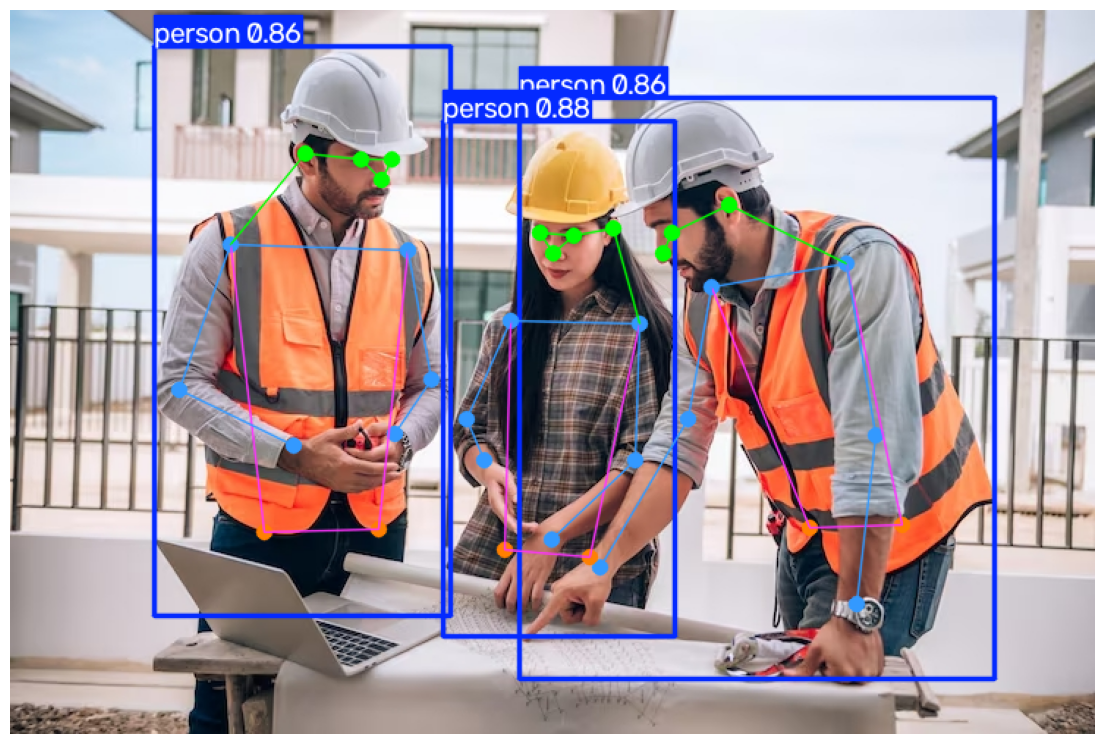

In [ ]:
import matplotlib.pyplot as plt

result = results[0]
annotated_image = result.plot()

plt.figure(figsize=(14, 10))
plt.imshow(annotated_image[:, :, ::-1])
plt.axis("off")
plt.show()

### Second approach

Pose model

In [32]:
from ultralytics import YOLO

pose_model = YOLO("yolo26n-pose.pt")


Define keypoints and area of the boxes where ppe must be

In [33]:

import numpy as np
import pandas as pd

KEYPOINTS = {
    "nose": 0,
    "left_eye": 1,
    "right_eye": 2,
    "left_shoulder": 5,
    "right_shoulder": 6,
    "left_elbow": 7,
    "right_elbow": 8,
    "left_wrist": 9,
    "right_wrist": 10,
    "left_hip": 11,
    "right_hip": 12,
    "left_ankle": 15,
    "right_ankle": 16
}


def make_region(centerx, centery, width, height, image_width, image_height):

    x1 = max(0, centerx - width / 2)
    y1 = max(0, centery - height / 2)

    x2 = min(image_width, centerx + width / 2)
    y2 = min(image_height, centery + height / 2)

    if x2 <= x1 or y2 <= y1:
        return None

    return np.array([x1, y1, x2, y2], dtype=float)


def get_person_regions(
    keypoints,
    keypoint_conf,
    person_box,
    image_width,
    image_height,
    min_kp_conf=0.25
):

    regions = {}

    person_width = person_box[2] - person_box[0]
    person_height = person_box[3] - person_box[1]

    if person_width <= 0 or person_height <= 0:
        return regions

    def valid(name):

        idx = KEYPOINTS[name]

        point = keypoints[idx]
        confidence = keypoint_conf[idx]

        if confidence is None or not np.isfinite(confidence):
            return False

        if confidence < min_kp_conf:
            return False

        if not np.all(np.isfinite(point)):
            return False

        return True

    def point(name):
        return keypoints[KEYPOINTS[name]]

    # HEAD / HELMET

    if valid("left_eye") and valid("right_eye"):

      left_eye = point("left_eye")
      right_eye = point("right_eye")

      eye_center_x = (left_eye[0] + right_eye[0]) / 2

      eye_center_y = (left_eye[1] + right_eye[1]) / 2

      head_top = person_box[1]
      head_bottom = eye_center_y

      head_width = max(
          np.linalg.norm(left_eye - right_eye) * 2.8,
          person_width * 0.12
      )

      regions["head"] = make_region(
          eye_center_x,
          (head_top + head_bottom) / 2,
          head_width,
          head_bottom - head_top,
          image_width,
          image_height
      )


    # EYES / GOOGLES

    if valid("left_eye") and valid("right_eye"):

        left_eye = point("left_eye")
        right_eye = point("right_eye")

        eye_distance = np.linalg.norm(
            left_eye - right_eye
        )

        eye_width = max(
            eye_distance * 1.6,
            person_width * 0.06
        )

        eye_height = max(
            eye_distance * 0.8,
            person_height * 0.025
        )

        center = (left_eye + right_eye) / 2

        regions["eyes"] = make_region(
            center[0],
            center[1],
            eye_width,
            eye_height,
            image_width,
            image_height
        )

    # TORSO / VEST

    torso_points = [
        name for name in [
            "left_shoulder",
            "right_shoulder",
            "left_hip",
            "right_hip"
        ]
        if valid(name)
    ]

    if len(torso_points) == 4:

        coords = np.array([
            point(name) for name in torso_points
        ])

        x1, y1 = coords.min(axis=0)
        x2, y2 = coords.max(axis=0)

        padding_x = person_width * 0.08
        padding_y = person_height * 0.04

        regions["torso"] = np.array([
            max(0, x1 - padding_x),
            max(0, y1 - padding_y),
            min(image_width, x2 + padding_x),
            min(image_height, y2 + padding_y)
        ], dtype=float)

    # HANDS / GLOVES

    for side in ["left", "right"]:

        elbow_name = f"{side}_elbow"
        wrist_name = f"{side}_wrist"

        if valid(elbow_name) and valid(wrist_name):

            elbow = point(elbow_name)
            wrist = point(wrist_name)

            forearm = wrist - elbow

            hand_center = wrist + forearm * 0.20

            hand_size = max(
                person_height * 0.12,
                person_width * 0.07
            )

            regions[f"{side}_glove"] = make_region(
                hand_center[0],
                hand_center[1],
                hand_size,
                hand_size,
                image_width,
                image_height
            )

    # FEET / BOOTS

    for side in ["left", "right"]:

        ankle_name = f"{side}_ankle"

        if valid(ankle_name):

            ankle = point(ankle_name)

            foot_width = max(
                person_width * 0.18,
                person_height * 0.07
            )

            foot_height = max(
                person_height * 0.13,
                person_width * 0.08
            )

            regions[f"{side}_boot"] = make_region(
                ankle[0],
                ankle[1] + foot_height * 0.30,
                foot_width,
                foot_height,
                image_width,
                image_height
            )

    return {
        name: region
        for name, region in regions.items()
        if region is not None
    }


Calculate overlap

In [34]:
def calculate_overlap(region_box, ppe_box):

    rx1, ry1, rx2, ry2 = region_box
    px1, py1, px2, py2 = ppe_box

    ix1 = max(rx1, px1)
    iy1 = max(ry1, py1)

    ix2 = min(rx2, px2)
    iy2 = min(ry2, py2)

    intersection = (
        max(0, ix2 - ix1) *
        max(0, iy2 - iy1)
    )

    ppe_area = max(
        1,
        (px2 - px1) * (py2 - py1)
    )

    return intersection / ppe_area


Mapping PPE

In [35]:
PPE_MAPPING = {

    "helmet": ["head"],
    "no_helmet": ["head"],

    "goggles": ["eyes"],
    "no_goggle": ["eyes"],

    "vest": ["torso"],
    "no_vest": ["torso"],

    "gloves": ["left_glove", "right_glove"],
    "no_gloves": ["left_glove", "right_glove"],

    "boots": ["left_boot", "right_boot"],
    "no_boots": ["left_boot", "right_boot"]
}


def get_ppe_segments(class_name):

    class_name = class_name.lower().strip()

    return PPE_MAPPING.get(class_name, [])


Analyze image

In [36]:
def analyze_ppe_image(
    model,
    pose_model,
    image_path,
    threshold=0.20,
    pose_conf=0.4,
    min_kp_conf=0.25,
    ambiguity_margin=0.05
):

    result = model.predict(
        source=image_path,
        conf=0.25,
        verbose=False
    )[0]

    image_height, image_width = result.orig_shape

    ppe_detections = []

    for i, box in enumerate(result.boxes):

        class_id = int(box.cls.item())

        ppe_detections.append({

            "ppe_id": i,
            "class_id": class_id,
            "class_name": result.names[class_id],
            "confidence": float(box.conf.item()),
            "box": box.xyxy[0].cpu().numpy()

        })


    pose_result = pose_model.predict(
        source=image_path,
        conf=pose_conf,
        verbose=False
    )[0]

    persons = []

    if (
        pose_result.keypoints is not None
        and pose_result.boxes is not None
        and len(pose_result.boxes) > 0
    ):

        keypoints = pose_result.keypoints.xy.cpu().numpy()

        keypoint_conf = (
            pose_result.keypoints.conf.cpu().numpy()
            if pose_result.keypoints.conf is not None
            else np.ones(keypoints.shape[:2])
        )

        pose_boxes = pose_result.boxes.xyxy.cpu().numpy()


        for person_id, (
            person_kp,
            person_kp_conf,
            person_box
        ) in enumerate(zip(
            keypoints,
            keypoint_conf,
            pose_boxes
        )):

            regions = get_person_regions(
                person_kp,
                person_kp_conf,
                person_box,
                image_width,
                image_height,
                min_kp_conf
            )

            persons.append({

                "person_id": person_id,
                "box": person_box,
                "keypoints": person_kp,
                "keypoint_conf": person_kp_conf,
                "segments": regions

            })


    associations = {
        person["person_id"]: []
        for person in persons
    }

    unassigned = []
    rows = []

    for detection in ppe_detections:

        ppe_box = detection["box"]

        possible_segments = get_ppe_segments(
            detection["class_name"]
        )

        candidates = []

        for person in persons:

            for segment_name in possible_segments:

                region = person["segments"].get(segment_name)

                if region is None:
                    continue

                score = calculate_overlap(
                    region,
                    ppe_box
                )

                if score > 0:

                    candidates.append({

                        "person_id": person["person_id"],
                        "segment": segment_name,
                        "overlap": score

                    })

        candidates.sort(
            key=lambda x: x["overlap"],
            reverse=True
        )

        best_match = candidates[0] if candidates else None

        second_match = (
            candidates[1] if len(candidates) > 1 else None
        )


        ambiguous = False

        if (
            best_match is not None
            and second_match is not None
            and best_match["person_id"] != second_match["person_id"]
            and (
                best_match["overlap"] -
                second_match["overlap"]
            ) < ambiguity_margin
        ):

            ambiguous = True

        assigned = (
            best_match is not None
            and best_match["overlap"] >= threshold
            and not ambiguous
        )

        if assigned:

            association = {
                **detection,
                **best_match
            }

            associations[
                best_match["person_id"]
            ].append(association)

            person_value = best_match["person_id"]
            segment_value = best_match["segment"]
            overlap_value = best_match["overlap"]
            status = "Assigned"

        else:

            unassigned_detection = {
                **detection,
                "reason": (
                    "Ambiguous"
                    if ambiguous
                    else "Insufficient overlap"
                    if best_match is not None
                    else "No valid region"
                )
            }

            unassigned.append(unassigned_detection)

            person_value = None
            segment_value = None

            overlap_value = (
                best_match["overlap"]
                if best_match is not None
                else 0
            )

            status = unassigned_detection["reason"]

        rows.append({

            "PPE": detection["class_name"],
            "Confidence": detection["confidence"],
            "Person": person_value,
            "Segment": segment_value,
            "Overlap": overlap_value,
            "Association": status

        })



    df = pd.DataFrame(rows)

    return df, associations, unassigned, result, persons


Person summary

In [37]:

def build_person_summary(persons, associations):

    ppe_types = [
        "helmet",
        "goggles",
        "vest",
        "gloves",
        "boots"
    ]

    rows = []

    for person in persons:

        person_id = person["person_id"]

        detections = associations.get(person_id, [])

        row = {
            "Person": person_id
        }

        for ppe in ppe_types:

            positive = any(
                d["class_name"].lower() == ppe
                for d in detections
            )

            negative = any(
                d["class_name"].lower() in {
                    f"no_{ppe}",
                    "no_goggle" if ppe == "goggles" else ""
                }
                for d in detections
            )

            if positive and negative:
                status = "Conflict"

            elif positive:
                status = "Detected"

            else:
                status = "Not detected"

            row[ppe.capitalize()] = status

        rows.append(row)

    return pd.DataFrame(rows)


Function visualize associations

In [38]:

import cv2
import matplotlib.pyplot as plt


def visualize_associations(
    image_path,
    persons,
    associations,
    unassigned=None
):

    image = cv2.imread(image_path)

    if image is None:
        print("Could not load image:", image_path)
        return

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )


    for person in persons:

        person_id = person["person_id"]

        x1, y1, x2, y2 = map(
            int,
            person["box"]
        )

        cv2.rectangle(
            image,
            (x1, y1),
            (x2, y2),
            (0, 180, 255),
            2
        )

        cv2.putText(
            image,
            f"Person {person_id}",
            (x1, max(15, y1 - 8)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 180, 255),
            2
        )

        for region_name, region_box in person["segments"].items():

            rx1, ry1, rx2, ry2 = map(
                int,
                region_box
            )

            cv2.rectangle(
                image,
                (rx1, ry1),
                (rx2, ry2),
                (0, 255, 0),
                1
            )

            cv2.putText(
                image,
                region_name,
                (rx1, max(12, ry1 - 3)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.35,
                (0, 255, 0),
                1
            )


    for person_id, detections in associations.items():

        for detection in detections:

            x1, y1, x2, y2 = map(
                int,
                detection["box"]
            )

            label = (
                f"{detection['class_name']} "
                f"P{person_id} "
                f"{detection['overlap']:.2f}"
            )

            cv2.rectangle(
                image,
                (x1, y1),
                (x2, y2),
                (255, 0, 0),
                2
            )

            cv2.putText(
                image,
                label,
                (x1, max(15, y1 - 5)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.45,
                (255, 0, 0),
                2
            )


    if unassigned is not None:

        for detection in unassigned:

            x1, y1, x2, y2 = map(
                int,
                detection["box"]
            )

            label = (
                f"{detection['class_name']} "
                f"UNASSIGNED"
            )

            cv2.rectangle(
                image,
                (x1, y1),
                (x2, y2),
                (255, 165, 0),
                2
            )

            cv2.putText(
                image,
                label,
                (x1, max(15, y1 - 5)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.45,
                (255, 165, 0),
                2
            )

    plt.figure(figsize=(14, 10))

    plt.imshow(image)
    plt.axis("off")
    plt.show()


Testing on images

In [39]:

from IPython.display import display

img_paths = [
    "/content/drive/MyDrive/PPE_Construction_YOLO/test/img1.jpg",
    "/content/drive/MyDrive/PPE_Construction_YOLO/test/img2.jpg",
    "/content/drive/MyDrive/PPE_Construction_YOLO/test/img3.jpg",
    "/content/drive/MyDrive/PPE_Construction_YOLO/test/img4.jpg"
]

results_by_image = {}

for image_path in img_paths:

    df, associations, unassigned, result, persons = analyze_ppe_image(
        model,
        pose_model,
        image_path,
        threshold=0.20,
        pose_conf=0.4,
        min_kp_conf=0.25
    )

    summary_df = build_person_summary(
        persons,
        associations
    )

    results_by_image[image_path] = {

        "df": df,
        "summary": summary_df,
        "associations": associations,
        "unassigned": unassigned,
        "result": result,
        "persons": persons

    }


    print("\nPERSON PPE SUMMARY:")
    display(summary_df)


    visualize_associations(
        image_path,
        persons,
        associations,
        unassigned
    )


Output hidden; open in https://colab.research.google.com to view.

This approach works better when persons are overlapping, as it is associated with the part of the body of each person instead of the person box